# Plots for calibration

In [2]:


import sys
sys.path.append("C:\scripts\Ephys analysis\ephys_pipeline")
import numpy as np
import scipy.io as scio
import matplotlib.pyplot as plt
from ephysSession import Session
from matplotlib.pyplot import figure
# import decon
from scipy.stats import chisquare
import pandas as pd
plt.rcParams['pdf.fonttype'] = '42' 
import random
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
cat = np.concatenate

In [90]:
allpaths = [
            [ r'K:\data\CW69\python\2025_12_19',
              ],
            [r'L:\data\CW68\python\2025_12_10',
              r'L:\data\CW68\python\2025_12_12',
              r'L:\data\CW68\python\2025_12_13',
              r'L:\data\CW68\python\2025_12_15',
              ],
            # [r'L:\data\CW70\python\2025_11_04',

            #  ],
            [r'G:\ephys_data\CW65\python\2025_02_25',
              ],
            [r'H:\ephys_data\CW47\python\2024_10_17',
              r'H:\ephys_data\CW47\python\2024_10_22',
              r'H:\ephys_data\CW47\python\2024_10_25',
              ],
            [r'K:\data\CW85\python\2026_02_07',
              r'K:\data\CW85\python\2026_02_10',
             
              ],
            [r'M:\data\CW87\python\2026_02_20',
              r'M:\data\CW87\python\2026_02_21',
              ],
            [r'K:\data\CW84\python\2026_03_11',
             r'K:\data\CW84\python\2026_03_14',
             r'K:\data\CW84\python\2026_03_15',
             r'K:\data\CW84\python\2026_03_16',
             r'K:\data\CW84\python\2026_03_17',
             r'K:\data\CW84\python\2026_03_18',
             r'K:\data\CW84\python\2026_03_19',
             r'K:\data\CW84\python\2026_03_20',
             ],

              [
              r'P:\data\CW92\python\2026_06_17',
              r'P:\data\CW92\python\2026_06_18',
              r'P:\data\CW92\python\2026_06_19',
              r'P:\data\CW92\python\2026_06_21',
              r'P:\data\CW92\python\2026_06_23',
              # r'P:\data\CW92\python\2026_06_24',
              r'P:\data\CW92\python\2026_06_25',
              r'P:\data\CW92\python\2026_06_26',
              r'P:\data\CW92\python\2026_06_27',
              # r'P:\data\CW92\python\2026_06_28',
              r'P:\data\CW92\python\2026_06_29',
              # r'P:\data\CW92\python\2026_06_30',
              r'P:\data\CW92\python\2026_07_01',

             ]
            ]
all_corrupted_paths = []

### VGAT

- blue laser calibration
- red laser calibration

Li et al 2016 (Figs S2, S5), Chen at al 2021 (Fig S3H)

### Waveforms examples and widths:

In [93]:
path

'P:\\data\\CW92\\python\\2026_07_01'

Loading good trial inds from file
16 trials removed for stability reasons
only ppyr neurons: 324 --> 277


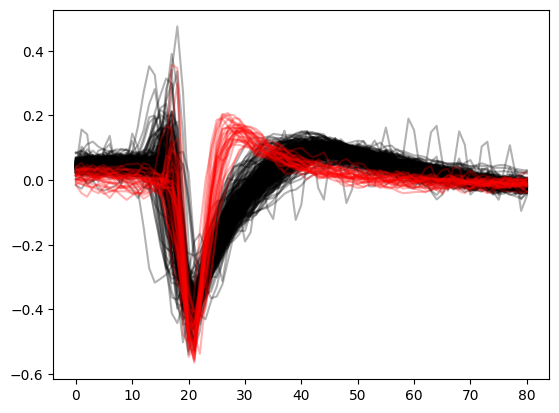

In [180]:
# path = r'L:\data\CW68\python\2025_12_10'
# s1 = Session(path, passive=False)

#%% Plot waveforms by cell type: FS and ppyr
path =r'P:\data\CW92\python\2026_06_24'
# path = r'L:\data\CW68\python\2025_12_12'
# path = r'H:\ephys_data\CW47\python\2024_10_25'
# path =r'M:\data\CW87\python\2026_02_21'
celltypes = [3,1] # FS and ppyr

f = plt.figure()
# for path in cat(all_learning_paths):
# for path in allpaths[-1]:

s1 = Session(path, passive=False, filter_by_stim=False)
for c in celltypes:
    neuron_cell_type = np.where(s1.celltype == c)[0]
    color = 'red' if c == 1 else 'black'
    for n in neuron_cell_type:
        
        plt.plot(np.arange(len(s1.get_single_waveform(n))),
                    s1.get_single_waveform(n),
                    color=color, alpha = 0.3)
plt.savefig(r'P:\paperfigures\fig1\example_spikewaves.pdf')

Loading good trial inds from file
31 trials removed for stability reasons
only ppyr neurons: 289 --> 246
Loading good trial inds from file
52 trials removed for stability reasons
only ppyr neurons: 188 --> 171
Loading good trial inds from file
18 trials removed for stability reasons
only ppyr neurons: 219 --> 180
Loading good trial inds from file
26 trials removed for stability reasons
only ppyr neurons: 233 --> 200
Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 172 --> 151
Loading good trial inds from file
61 trials removed for stability reasons
only ppyr neurons: 236 --> 189
Remove 0 trials from session for bad behavior
15 trials removed for stability reasons
only ppyr neurons: 253 --> 216
Remove 0 trials from session for bad behavior
6 trials removed for stability reasons
only ppyr neurons: 226 --> 198
Remove 0 trials from session for bad behavior
7 trials removed for stability reasons
only ppyr neurons: 308 --> 267
Remove 0 trials from s

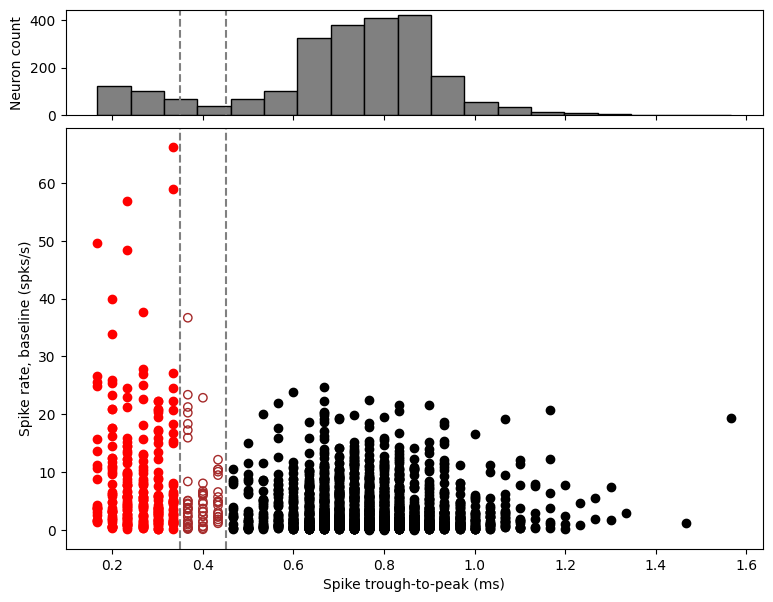

In [182]:
import matplotlib.gridspec as gridspec

# Set up a figure with two subplots, histogram on top (ax1), scatter below (ax2), sharing x axis
f = plt.figure(figsize=(9,7))
gs = gridspec.GridSpec(2, 1, height_ratios=[1, 4], hspace=0.05)
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1], sharex=ax1)

widths = []
spkrt_baseline = []

# for path in cat(all_learning_paths):
for path in allpaths[-1]:

    s1 = Session(path, passive=False, filter_by_stim=False)

    for n in range(s1.num_neurons): 
        width = s1.get_waveform_width(n)
        widths += [width]
        all_stable_trials = [t for t in range(s1.num_trials) if t in s1.stable_trials[n]]
        baseline = s1.get_spike_rate(n, (0.07, 0.57), all_stable_trials)
        spkrt_baseline += baseline
        # Scatter plot on ax2
        if width < 0.35:
            ax2.scatter(width, baseline, color='red')
        elif width > 0.45:
            ax2.scatter(width, baseline, color='black')
        else:
            ax2.scatter(width, baseline, facecolors='none', edgecolors='brown')

# Histogram plot on ax1
bin_edges = np.linspace(min(widths), max(widths), 20)
ax1.hist(widths, bins=bin_edges, color='gray', edgecolor='k')
ax1.set_ylabel('Neuron count')
ax1.xaxis.set_tick_params(labelbottom=False)  # Hide x-axis labels for histogram

# Mark width category boundaries on both axes
for ax in [ax1, ax2]:
    ax.axvline(0.35, color='grey', ls = '--')
    ax.axvline(0.45, color='grey', ls = '--')

ax2.set_ylabel('Spike rate, baseline (spks/s)')
ax2.set_xlabel('Spike trough-to-peak (ms)')

# Remove space between subplots for better appearance
plt.setp(ax1.get_xticklabels(), visible=False)

plt.savefig(r'P:\paperfigures\fig1\spike_width.pdf')

In [131]:
stats.ttest_ind(s1.get_spike_count(n, early_window, stim_trials), s1.get_spike_count(n, early_window, s1.i_good_non_stim_trials), equal_var=False)
s1.get_spike_count(n, early_window, s1.i_good_non_stim_trials)

[1,
 4,
 2,
 0,
 0,
 0,
 0,
 2,
 1,
 4,
 0,
 0,
 1,
 1,
 2,
 3,
 5,
 4,
 1,
 0,
 3,
 5,
 3,
 3,
 1,
 1,
 2,
 4,
 2,
 1,
 7,
 0,
 0,
 3,
 2,
 0,
 3,
 0,
 2,
 2,
 0,
 0,
 0,
 2,
 1,
 3,
 3,
 0,
 0,
 4,
 0,
 6,
 1,
 2,
 1,
 2,
 2,
 1,
 2,
 0,
 3,
 1,
 0,
 0,
 2,
 1,
 1,
 1,
 6,
 0,
 1,
 4,
 1,
 0,
 1,
 0,
 3,
 1,
 1,
 2,
 4,
 0,
 2,
 0,
 0,
 3,
 2,
 6,
 1,
 3,
 2,
 3,
 0,
 0,
 3,
 2,
 0,
 1,
 3,
 0,
 2,
 1,
 2,
 4,
 2,
 4,
 2,
 0,
 2,
 0,
 0,
 4,
 2,
 0,
 0,
 0,
 0,
 1,
 2,
 2,
 1,
 4,
 3,
 2,
 1,
 0,
 2,
 5,
 2,
 1,
 3,
 0,
 1,
 7,
 1,
 0,
 2,
 2,
 0,
 0,
 1,
 1,
 0,
 1,
 3,
 2,
 2,
 3,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 3,
 2,
 0,
 0,
 1,
 2,
 4,
 1,
 2,
 0,
 0,
 1,
 0,
 1,
 0,
 2,
 2,
 2,
 3,
 3,
 1,
 1,
 1,
 1,
 0,
 1,
 3,
 3,
 0,
 3,
 0,
 3,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 6,
 0,
 3,
 3,
 1,
 1,
 4,
 5,
 1,
 0,
 0,
 0]

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 216 --> 175


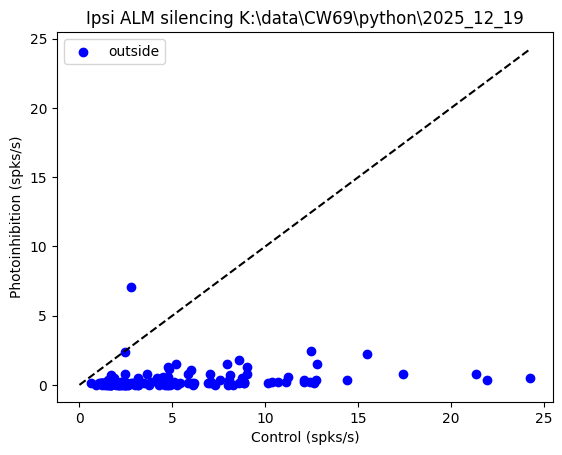

Loading good trial inds from file
7 trials removed for stability reasons
only ppyr neurons: 305 --> 264


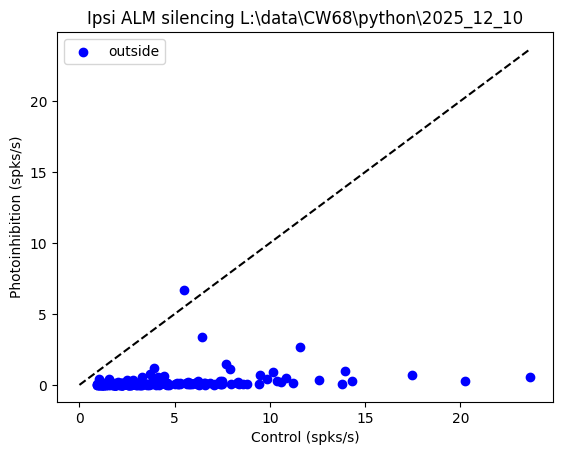

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 422 --> 361


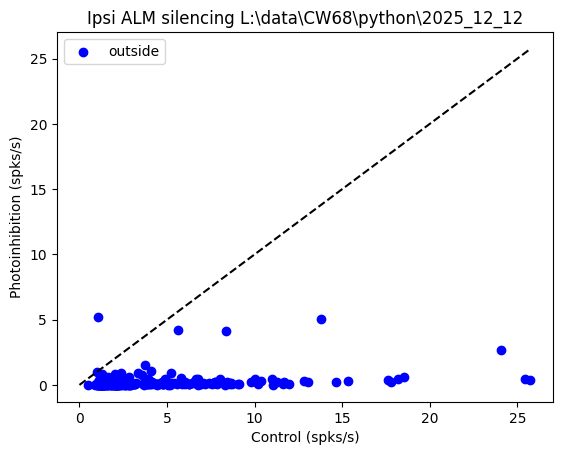

Loading good trial inds from file
20 trials removed for stability reasons
only ppyr neurons: 328 --> 279


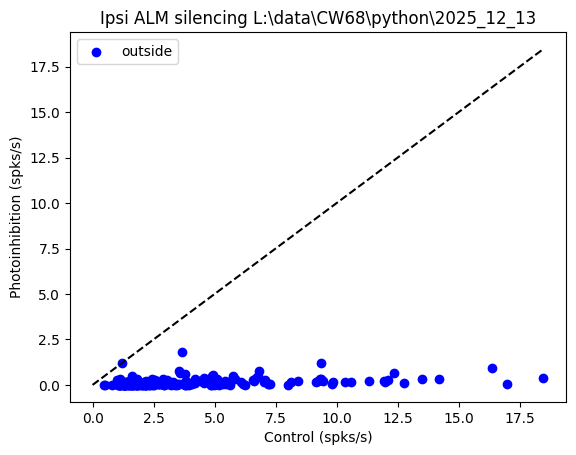

Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 178 --> 151


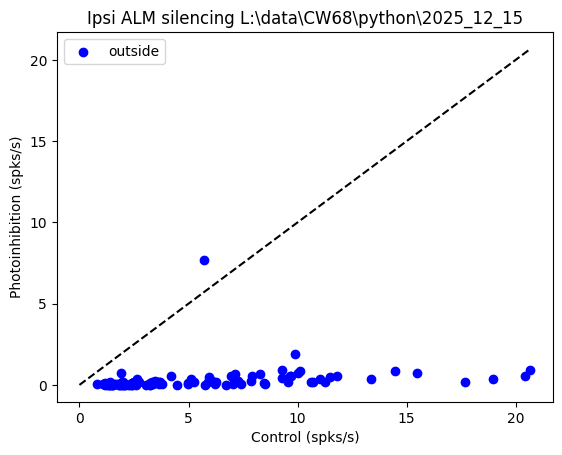

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 407 --> 344


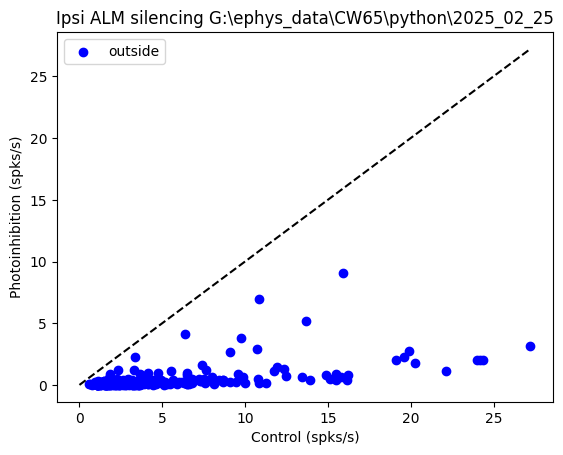

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 271 --> 238


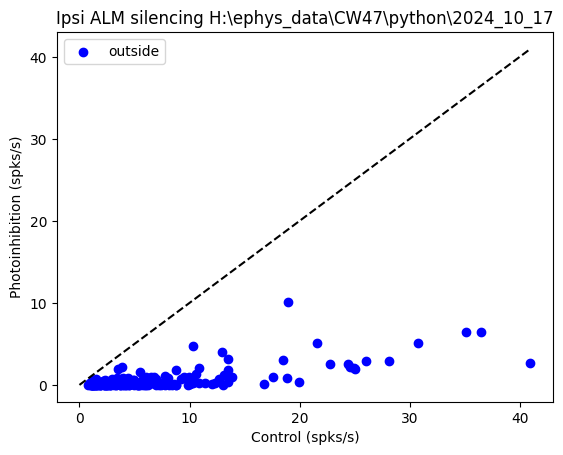

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 344 --> 287


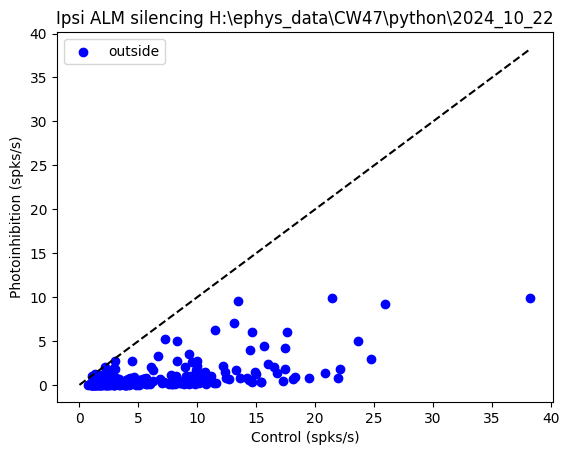

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 349 --> 287


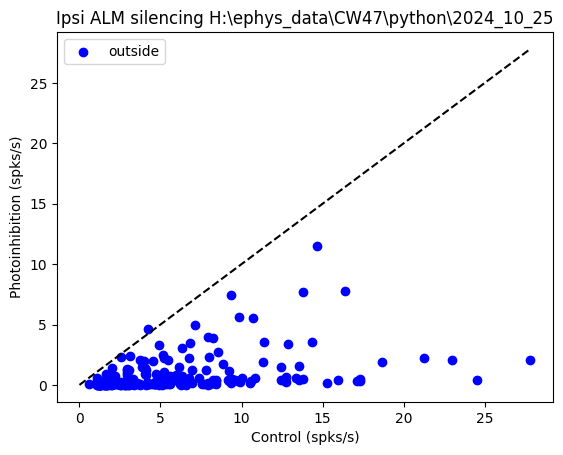

Loading good trial inds from file
4 trials removed for stability reasons
only ppyr neurons: 249 --> 205


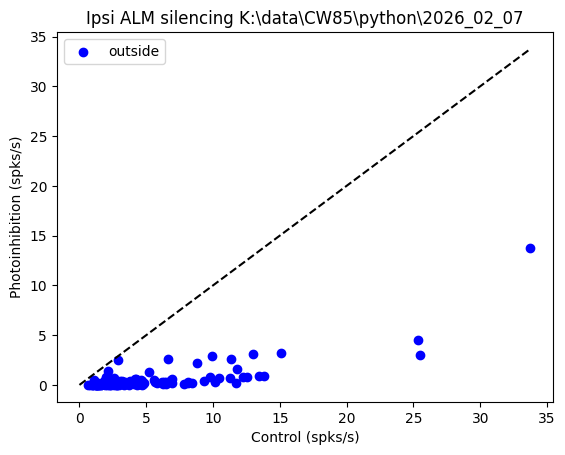

Loading good trial inds from file
14 trials removed for stability reasons
only ppyr neurons: 173 --> 145


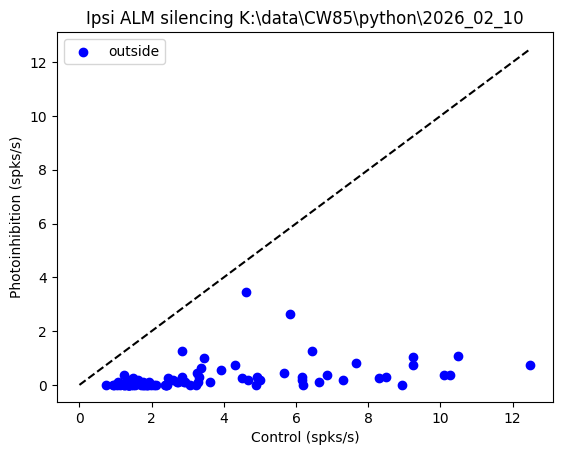

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 343 --> 292


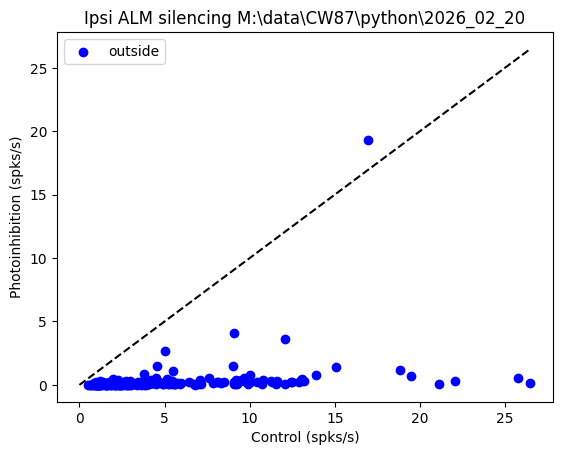

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 516 --> 429


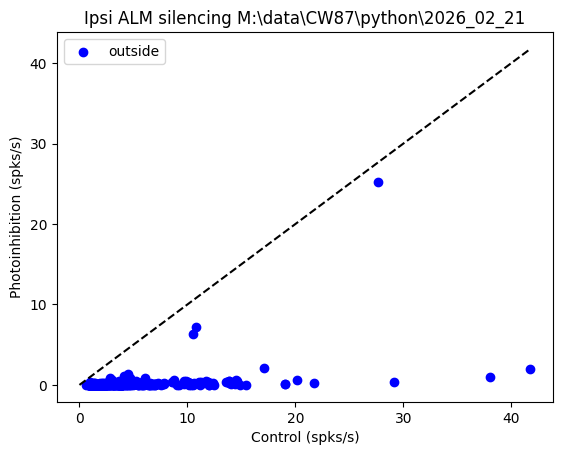

Loading good trial inds from file
15 trials removed for stability reasons
only ppyr neurons: 361 --> 303


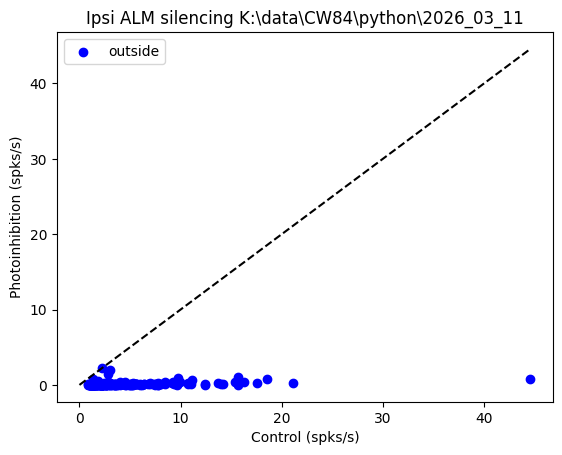

Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 192 --> 145


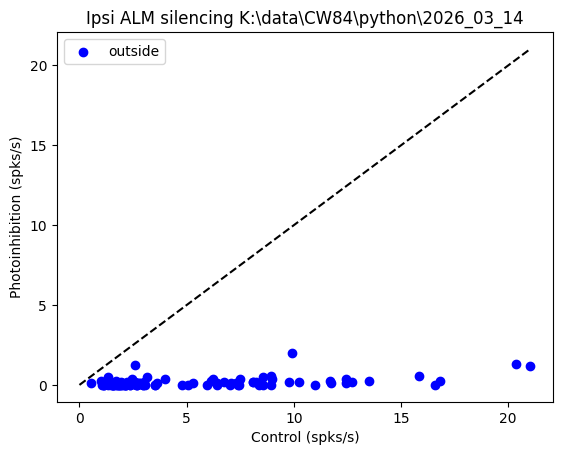

Loading good trial inds from file
28 trials removed for stability reasons
only ppyr neurons: 504 --> 417


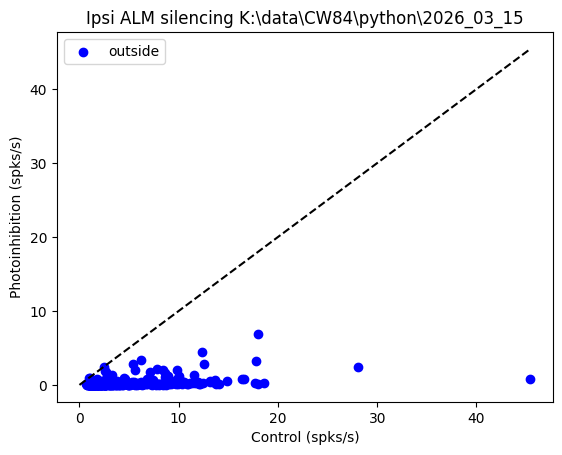

Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 368 --> 302


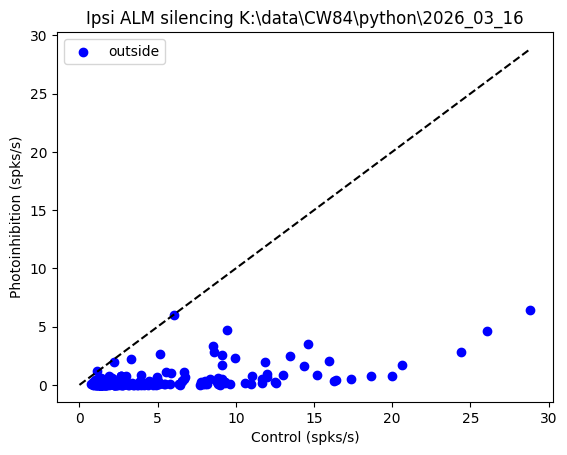

Loading good trial inds from file
32 trials removed for stability reasons
only ppyr neurons: 218 --> 181


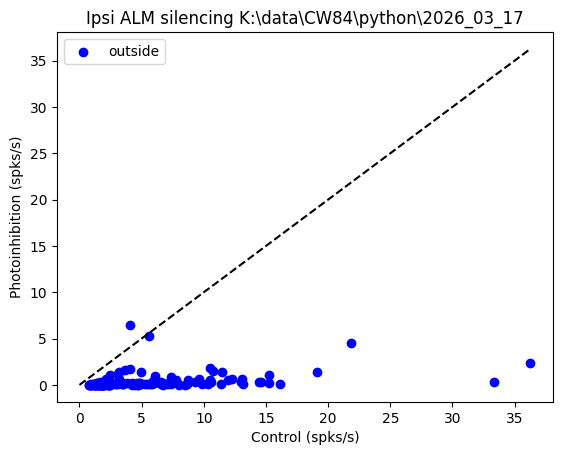

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 203 --> 168


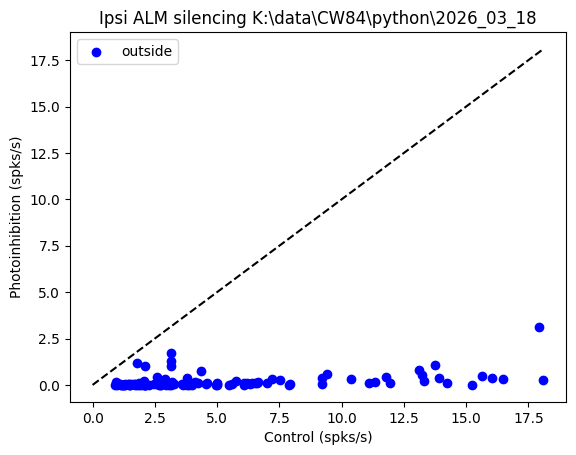

Loading good trial inds from file
6 trials removed for stability reasons
only ppyr neurons: 362 --> 280


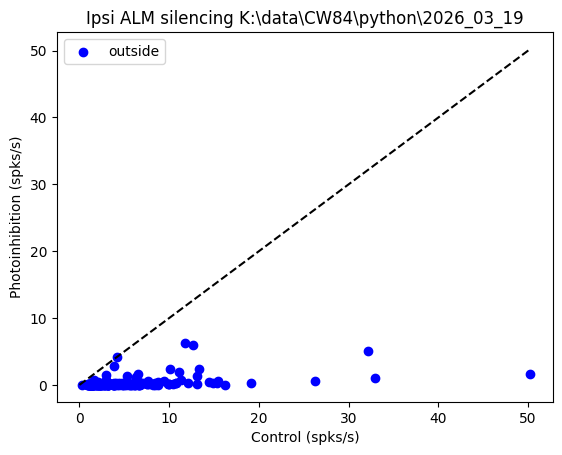

Loading good trial inds from file
10 trials removed for stability reasons
only ppyr neurons: 206 --> 167


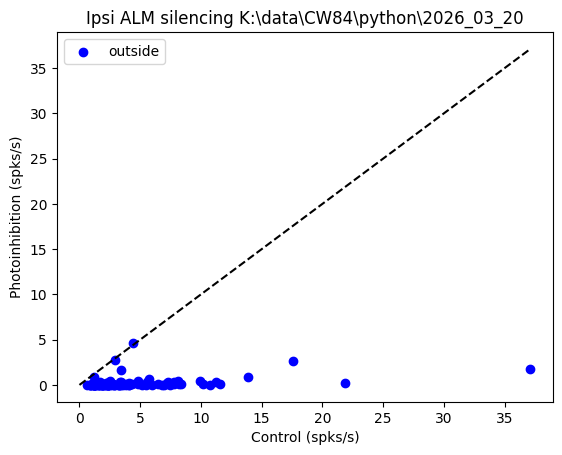

Loading good trial inds from file
31 trials removed for stability reasons
only ppyr neurons: 289 --> 226


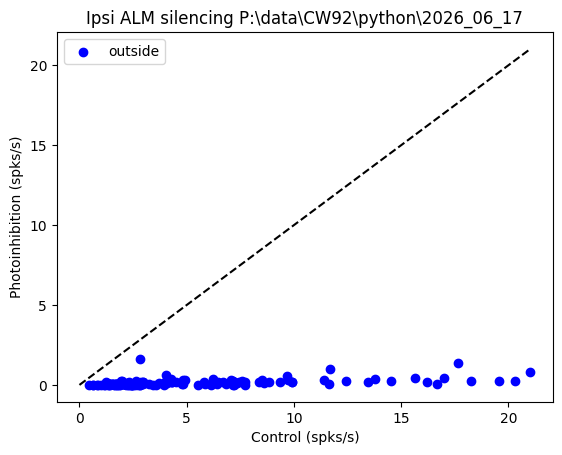

Loading good trial inds from file
52 trials removed for stability reasons
only ppyr neurons: 188 --> 165


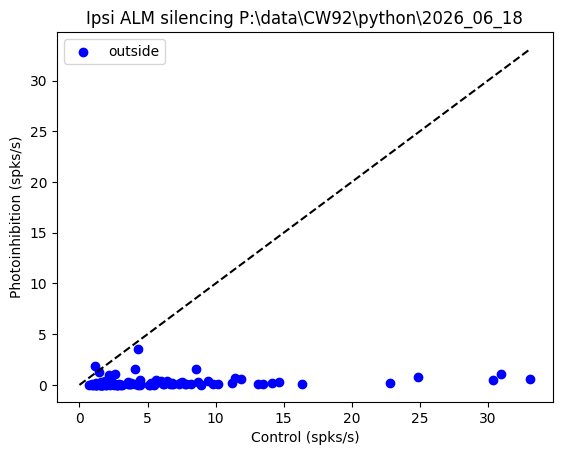

Loading good trial inds from file
18 trials removed for stability reasons
only ppyr neurons: 219 --> 174


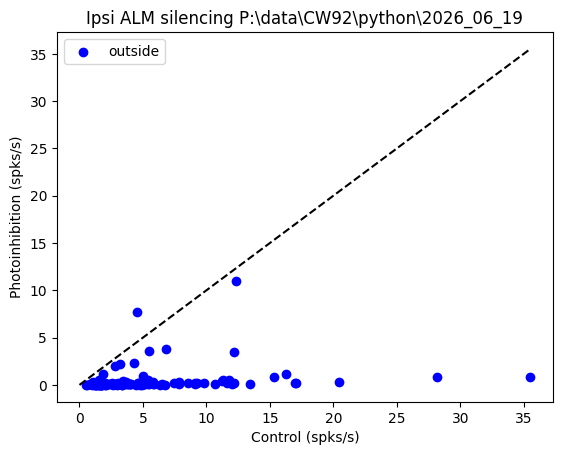

Loading good trial inds from file
26 trials removed for stability reasons
only ppyr neurons: 233 --> 186


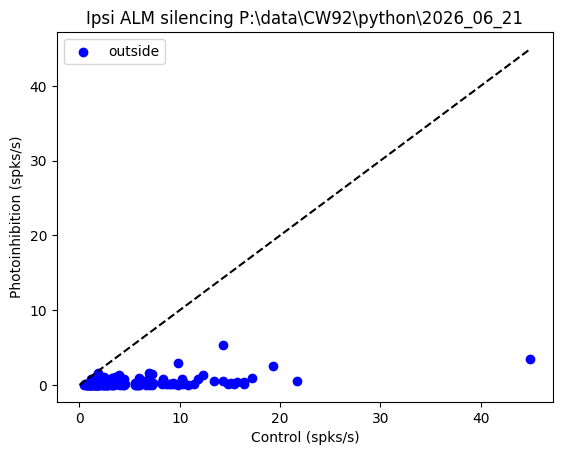

Loading good trial inds from file
0 trials removed for stability reasons
only ppyr neurons: 172 --> 144


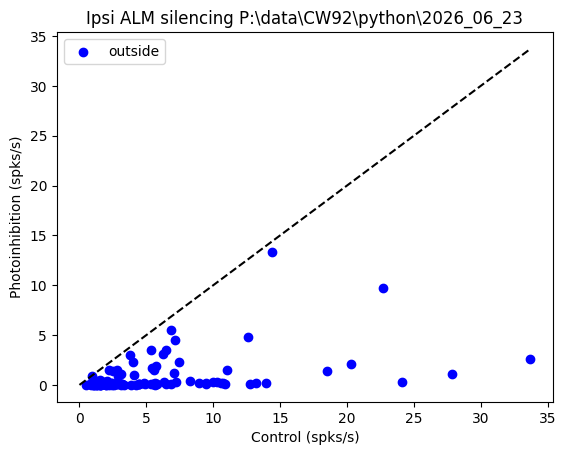

Loading good trial inds from file
61 trials removed for stability reasons
only ppyr neurons: 236 --> 171


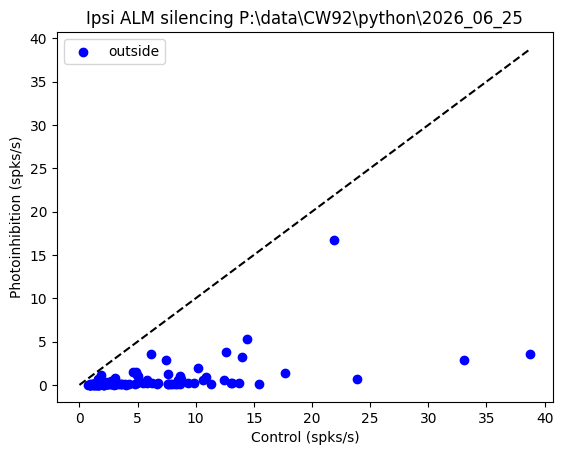

15 trials removed for stability reasons
only ppyr neurons: 253 --> 201


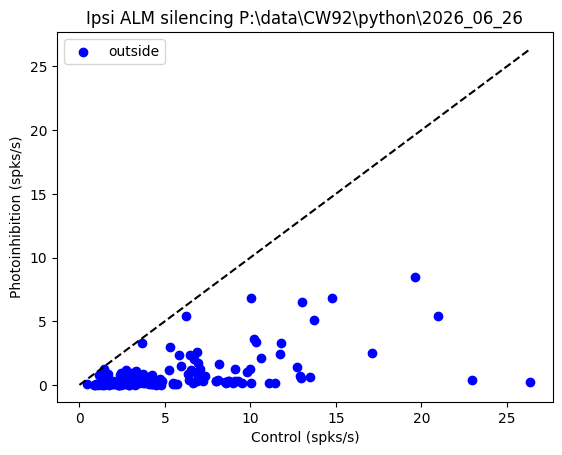

6 trials removed for stability reasons
only ppyr neurons: 226 --> 186


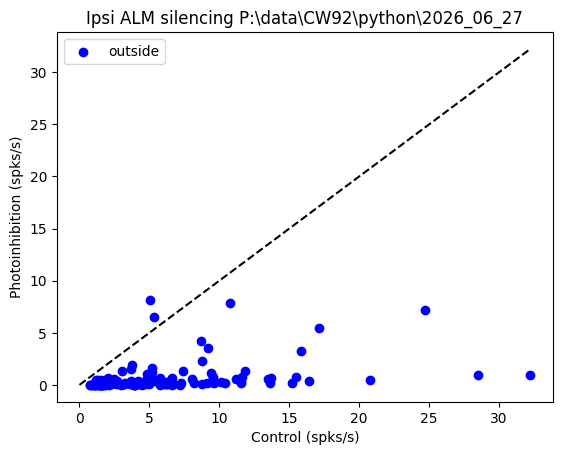

7 trials removed for stability reasons
only ppyr neurons: 308 --> 248


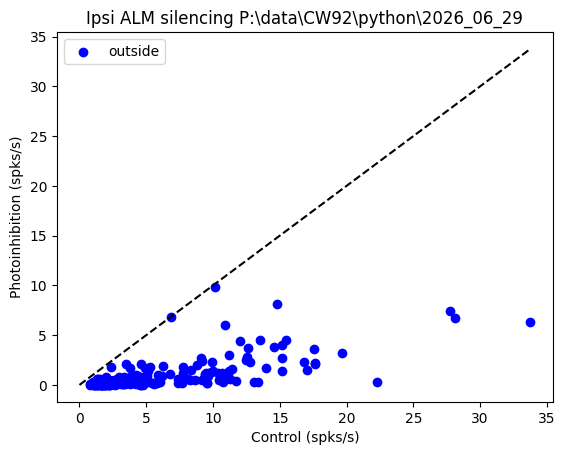

2 trials removed for stability reasons
only ppyr neurons: 194 --> 147


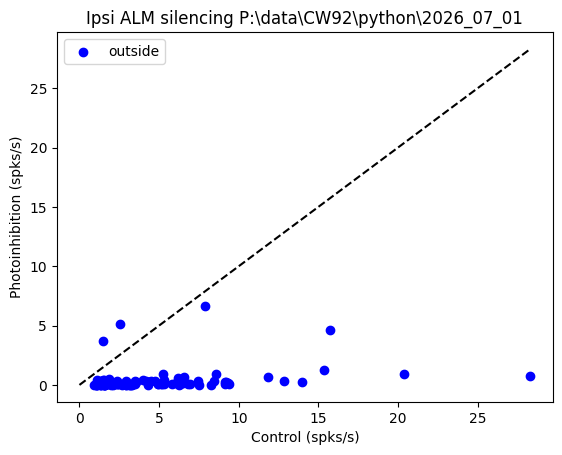

In [132]:
all_ipsi_spks_first_500ms, all_contra_spks_first_500ms = [],[]
all_ipsi_spks_last_500ms, all_contra_spks_last_500ms = [],[]
all_ipsi_spks_first_500ms_sig, all_contra_spks_first_500ms_sig = [],[]
all_ipsi_spks_last_500ms_sig, all_contra_spks_last_500ms_sig = [],[]

for path in cat(allpaths):    
    # if 'CW47' not in path and 'CW65' not in path:
    #     continue
    ctl_spk_first_500ms, ipsi_spk_first_500ms, contra_spk_first_500ms = [],[],[]
    ctl_spk_last_500ms, ipsi_spk_last_500ms, contra_spk_last_500ms = [],[],[]

    ipsi_spk_first_500ms_sig, ipsi_spk_last_500ms_sig = [],[]
    contra_spk_first_500ms_sig, contra_spk_last_500ms_sig = [],[]


    center_idx = []
    s1 = Session(path, passive=False, filter_by_stim=True, filter_low_perf=False)#, side='R')


    sided_neurons = s1.R_alm_idx
    # stim_trials = s1.i_good_bi_stim_trials # s1.i_good_L_stim_trials
    stim_trials = s1.i_good_R_stim_trials
    
    early_window = (0.570 + 1.3 + 0, 0.570 + 1.3 + 0.5) # First 500ms of delay
    late_window = (0.570 + 1.3 + 0.5, 0.570 + 1.3 + 1.0) # First 500ms of delay
    if 'CW47' in path or 'CW65' in path:
        early_window = (0.570 + 1.4 + 0, 0.570 + 1.4 + 0.5) # First 500ms of delay
        late_window = (0.570 + 1.4 + 0.5, 0.570 + 1.4 + 1.0) # First 500ms of delay
    
    # window = (0.570 + 1.2 + 0, 0.570 + 1.2 + 0.8) # First 0.8s of delay
    counter = 0
    for n in sided_neurons:
        # if s1.shank[n] == 1 or s1.shank[n] == 4:
        #     center_idx += [n]
        #     continue 
        ctl_rate = s1.get_spike_rate(n, (0.570 + 1.3 + 0, 0.570 + 1.3 + 1.0), s1.i_good_non_stim_trials)

        if ctl_rate < 1:
            continue
        ipsi_spk_first_500ms += [s1.get_spike_rate(n, early_window, stim_trials)]
        ipsi_spk_last_500ms += [s1.get_spike_rate(n, late_window, stim_trials)]
        contra_spk_first_500ms += [s1.get_spike_rate(n, early_window, s1.i_good_L_stim_trials)]
        contra_spk_last_500ms += [s1.get_spike_rate(n, late_window, s1.i_good_L_stim_trials)]
        ctl_spk_first_500ms += [s1.get_spike_rate(n, early_window, s1.i_good_non_stim_trials)]
        ctl_spk_last_500ms += [s1.get_spike_rate(n, late_window, s1.i_good_non_stim_trials)]

        # Perform a two-tailed t-test between stim trial spike rates and control trial spike rates.
        # Assign 1 if two-tailed p < 0.01, else 0.

        t_stat, p_val = stats.ttest_ind(s1.get_spike_count(n, early_window, stim_trials), s1.get_spike_count(n, early_window, s1.i_good_non_stim_trials), equal_var=False)
        ipsi_spk_first_500ms_sig.append(1 if p_val < 0.01 else 0)
        t_stat, p_val = stats.ttest_ind(s1.get_spike_count(n, late_window, stim_trials), s1.get_spike_count(n, late_window, s1.i_good_non_stim_trials), equal_var=False)
        ipsi_spk_last_500ms_sig.append(1 if p_val < 0.01 else 0)
        t_stat, p_val = stats.ttest_ind(s1.get_spike_count(n, early_window, s1.i_good_L_stim_trials), s1.get_spike_count(n, early_window, s1.i_good_non_stim_trials), equal_var=False)
        contra_spk_first_500ms_sig.append(1 if p_val < 0.01 else 0)
        t_stat, p_val = stats.ttest_ind(s1.get_spike_count(n, late_window, s1.i_good_L_stim_trials), s1.get_spike_count(n, late_window, s1.i_good_non_stim_trials), equal_var=False)
        contra_spk_last_500ms_sig.append(1 if p_val < 0.01 else 0)


        if s1.shank[n] == 2 or s1.shank[n] == 3:
            center_idx += [counter]
            
        counter += 1
    
    
    
    sided_neurons = s1.L_alm_idx
    # stim_trials = s1.i_good_bi_stim_trials # s1.i_good_L_stim_trials
    stim_trials = s1.i_good_L_stim_trials

    counter = 0
    for n in sided_neurons:
        # if s1.shank[n] == 1 or s1.shank[n] == 4:
        #     center_idx += [n]
        #     continue 
        ctl_rate = s1.get_spike_rate(n, (0.570 + 1.3 + 0, 0.570 + 1.3 + 1.0), s1.i_good_non_stim_trials)
        if ctl_rate < 1:
            continue
        ipsi_spk_last_500ms += [s1.get_spike_rate(n, late_window, stim_trials)]
        ipsi_spk_first_500ms += [s1.get_spike_rate(n, early_window, stim_trials)]
        contra_spk_first_500ms += [s1.get_spike_rate(n, early_window, s1.i_good_R_stim_trials)]
        contra_spk_last_500ms += [s1.get_spike_rate(n, late_window, s1.i_good_R_stim_trials)]
        ctl_spk_first_500ms += [s1.get_spike_rate(n, early_window, s1.i_good_non_stim_trials)]
        ctl_spk_last_500ms += [s1.get_spike_rate(n, late_window, s1.i_good_non_stim_trials)]


        t_stat, p_val = stats.ttest_ind(s1.get_spike_count(n, early_window, stim_trials), s1.get_spike_count(n, early_window, s1.i_good_non_stim_trials), equal_var=False)
        ipsi_spk_first_500ms_sig.append(1 if p_val < 0.01 else 0)
        t_stat, p_val = stats.ttest_ind(s1.get_spike_count(n, late_window, stim_trials), s1.get_spike_count(n, late_window, s1.i_good_non_stim_trials), equal_var=False)
        ipsi_spk_last_500ms_sig.append(1 if p_val < 0.01 else 0)
        t_stat, p_val = stats.ttest_ind(s1.get_spike_count(n, early_window, s1.i_good_R_stim_trials), s1.get_spike_count(n, early_window, s1.i_good_non_stim_trials), equal_var=False)
        contra_spk_first_500ms_sig.append(1 if p_val < 0.01 else 0)
        t_stat, p_val = stats.ttest_ind(s1.get_spike_count(n, late_window, s1.i_good_R_stim_trials), s1.get_spike_count(n, late_window, s1.i_good_non_stim_trials), equal_var=False)
        contra_spk_last_500ms_sig.append(1 if p_val < 0.01 else 0)


        if s1.shank[n] == 2 or s1.shank[n] == 3:
            center_idx += [counter]
            
        counter += 1
        
        
    f = plt.figure()
    plt.scatter(ctl_spk_first_500ms, ipsi_spk_first_500ms, color='blue', label ='outside')
    plt.plot([0, max(ctl_spk_first_500ms)], [0, max(ctl_spk_first_500ms)], ls='--', color='black')
    plt.ylabel('Photoinhibition (spks/s)')
    plt.xlabel('Control (spks/s)')
    plt.title('Ipsi ALM silencing {}'.format(path))
    plt.legend()
    plt.show()

    all_ipsi_spks_first_500ms += [(ipsi_spk_first_500ms, ctl_spk_first_500ms)]
    all_contra_spks_first_500ms += [(contra_spk_first_500ms, ctl_spk_first_500ms)]
    all_ipsi_spks_last_500ms += [(ipsi_spk_last_500ms, ctl_spk_last_500ms)]
    all_contra_spks_last_500ms += [(contra_spk_last_500ms, ctl_spk_last_500ms)]

    all_ipsi_spks_first_500ms_sig += [ipsi_spk_first_500ms_sig]
    all_ipsi_spks_last_500ms_sig += [ipsi_spk_last_500ms_sig]
    all_contra_spks_first_500ms_sig += [contra_spk_first_500ms_sig]
    all_contra_spks_last_500ms_sig += [contra_spk_last_500ms_sig]


    

In [152]:
sum(cat(all_ipsi_spks_first_500ms_sig))

len(all_ipsi_spks_first_500ms_sig[0])
len(all_ipsi_spks_first_500ms[0])

len(all_ipsi_spks_first_500ms[10][1])

86

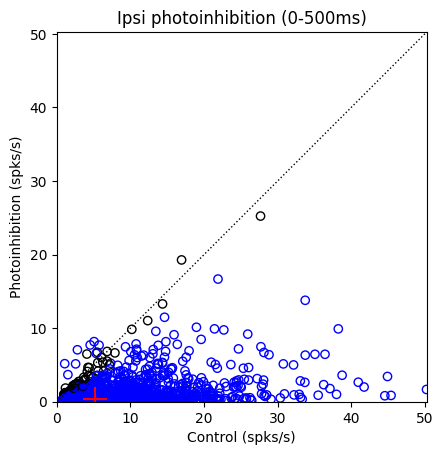

In [155]:
f = plt.figure()
for i in range(len(all_ipsi_spks_first_500ms)):
    for n in range(len(all_ipsi_spks_first_500ms_sig[i])):
        if all_ipsi_spks_first_500ms_sig[i][n]:
            plt.scatter(all_ipsi_spks_first_500ms[i][1][n], all_ipsi_spks_first_500ms[i][0][n], facecolors='none', edgecolors='blue')
        else:
            plt.scatter(all_ipsi_spks_first_500ms[i][1][n], all_ipsi_spks_first_500ms[i][0][n], facecolors='none', edgecolors='black')

# Adjust axes to match x and y spans, draw a diagonal dotted line, and set aspect ratio to square


# Find all data points for x and y across all groups
x_vals = np.concatenate([np.array(pair[1]) for pair in all_ipsi_spks_first_500ms])
y_vals = np.concatenate([np.array(pair[0]) for pair in all_ipsi_spks_first_500ms])

# Compute mean of all x and y values across the groups
mean_x = np.mean(x_vals)
mean_y = np.mean(y_vals)
# Plot the mean as a cross in red (or any distinguishable color)
plt.scatter(mean_x, mean_y, marker='+', color='red', s=300)

# Determine the global min/max for axes
min_val = min(x_vals.min(), y_vals.min())
max_val = max(x_vals.max(), y_vals.max())

# Set axes to be equal and square
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.gca().set_aspect('equal', adjustable='box')

# Add a diagonal dotted line across the square span
plt.plot([min_val, max_val], [min_val, max_val], 'k:', linewidth=1)
plt.title('Ipsi photoinhibition (0-500ms)')
plt.xlabel('Control (spks/s)')
plt.ylabel('Photoinhibition (spks/s)')
plt.savefig(r'P:\paperfigures\fig1\ipsi_photoinhibi_first500ms.pdf')
plt.show()



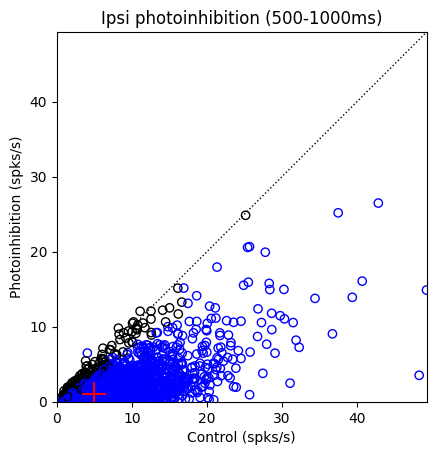

In [156]:
f = plt.figure()
for i in range(len(all_ipsi_spks_last_500ms)):
    for n in range(len(all_ipsi_spks_last_500ms_sig[i])):
        if all_ipsi_spks_last_500ms_sig[i][n]:
            plt.scatter(all_ipsi_spks_last_500ms[i][1][n], all_ipsi_spks_last_500ms[i][0][n], facecolors='none', edgecolors='blue', label='outside')
        else:
            plt.scatter(all_ipsi_spks_last_500ms[i][1][n], all_ipsi_spks_last_500ms[i][0][n], facecolors='none', edgecolors='black', label='outside')

# Adjust axes to match x and y spans, draw a diagonal dotted line, and set aspect ratio to square

# Find all data points for x and y across all groups
x_vals = np.concatenate([np.array(pair[1]) for pair in all_ipsi_spks_last_500ms])
y_vals = np.concatenate([np.array(pair[0]) for pair in all_ipsi_spks_last_500ms])
# Compute mean of all x and y values across the groups
mean_x = np.mean(x_vals)
mean_y = np.mean(y_vals)
# Plot the mean as a cross in red (or any distinguishable color)
plt.scatter(mean_x, mean_y, marker='+', color='red', s=300)

# Determine the global min/max for axes
min_val = min(x_vals.min(), y_vals.min())
max_val = max(x_vals.max(), y_vals.max())

# Set axes to be equal and square
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.gca().set_aspect('equal', adjustable='box')

# Add a diagonal dotted line across the square span
plt.plot([min_val, max_val], [min_val, max_val], 'k:', linewidth=1)
plt.title('Ipsi photoinhibition (500-1000ms)')
plt.xlabel('Control (spks/s)')
plt.ylabel('Photoinhibition (spks/s)')
plt.savefig(r'P:\paperfigures\fig1\ipsi_photoinhibi_last500ms.pdf')
plt.show()


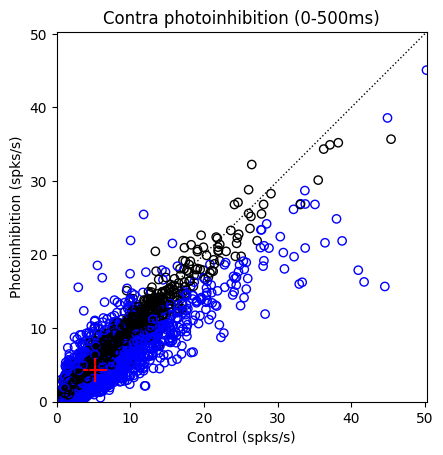

In [157]:
f = plt.figure()
for i in range(len(all_contra_spks_first_500ms)):
    for n in range(len(all_contra_spks_first_500ms_sig[i])):
        if all_contra_spks_first_500ms_sig[i][n]:
            plt.scatter(all_contra_spks_first_500ms[i][1][n], all_contra_spks_first_500ms[i][0][n], facecolors='none', edgecolors='blue', label='outside')
        else:
            plt.scatter(all_contra_spks_first_500ms[i][1][n], all_contra_spks_first_500ms[i][0][n], facecolors='none', edgecolors='black', label='outside')
# Adjust axes to match x and y spans, draw a diagonal dotted line, and set aspect ratio to square

# Find all data points for x and y across all groups
x_vals = np.concatenate([np.array(pair[1]) for pair in all_contra_spks_first_500ms])
y_vals = np.concatenate([np.array(pair[0]) for pair in all_contra_spks_first_500ms])
# Compute mean of all x and y values across the groups
mean_x = np.mean(x_vals)
mean_y = np.mean(y_vals)
# Plot the mean as a cross in red (or any distinguishable color)
plt.scatter(mean_x, mean_y, marker='+', color='red', s=300)

# Determine the global min/max for axes
min_val = min(x_vals.min(), y_vals.min())
max_val = max(x_vals.max(), y_vals.max())

# Set axes to be equal and square
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.gca().set_aspect('equal', adjustable='box')

# Add a diagonal dotted line across the square span
plt.plot([min_val, max_val], [min_val, max_val], 'k:', linewidth=1)
plt.title('Contra photoinhibition (0-500ms)')
plt.xlabel('Control (spks/s)')
plt.ylabel('Photoinhibition (spks/s)')
plt.savefig(r'P:\paperfigures\fig1\contra_photoinhibi_first500ms.pdf')
plt.show()


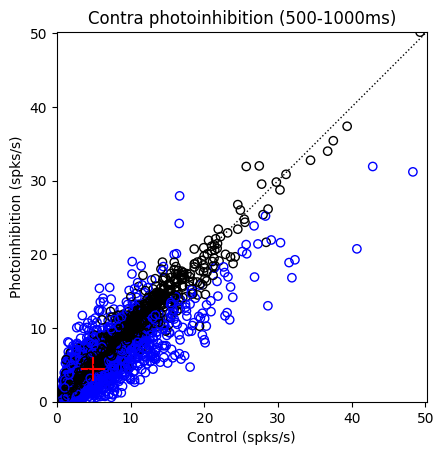

In [159]:
f = plt.figure()
for i in range(len(all_contra_spks_last_500ms)):
    for n in range(len(all_contra_spks_last_500ms_sig[i])):
        if all_contra_spks_last_500ms_sig[i][n]:

            plt.scatter(all_contra_spks_last_500ms[i][1][n], all_contra_spks_last_500ms[i][0][n], facecolors='none', edgecolors='blue', label='outside')
        else:
            plt.scatter(all_contra_spks_last_500ms[i][1][n], all_contra_spks_last_500ms[i][0][n], facecolors='none', edgecolors='black', label='outside')

# Adjust axes to match x and y spans, draw a diagonal dotted line, and set aspect ratio to square

# Find all data points for x and y across all groups
x_vals = np.concatenate([np.array(pair[1]) for pair in all_contra_spks_last_500ms])
y_vals = np.concatenate([np.array(pair[0]) for pair in all_contra_spks_last_500ms])
# Compute mean of all x and y values across the groups
mean_x = np.mean(x_vals)
mean_y = np.mean(y_vals)
# Plot the mean as a cross in red (or any distinguishable color)
plt.scatter(mean_x, mean_y, marker='+', color='red', s=300)

# Determine the global min/max for axes
min_val = min(x_vals.min(), y_vals.min())
max_val = max(x_vals.max(), y_vals.max())

# Set axes to be equal and square
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.gca().set_aspect('equal', adjustable='box')

# Add a diagonal dotted line across the square span
plt.plot([min_val, max_val], [min_val, max_val], 'k:', linewidth=1)
plt.title('Contra photoinhibition (500-1000ms)')
plt.xlabel('Control (spks/s)')
plt.ylabel('Photoinhibition (spks/s)')
plt.savefig(r'P:\paperfigures\fig1\contra_photoinhibi_last500ms.pdf')
plt.show()


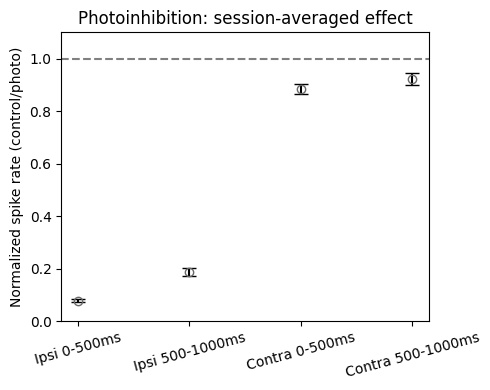

In [73]:
# average photoinhibition across sessions


# First 500ms subplot
import scipy.stats

# Compute mean and SEM for each condition across sessions

def get_ratios(arr):
    # Computes control/photo ratio for all sessions
    return np.array([np.mean(np.array(x[0]) / np.array(x[1])) for x in arr])

def get_ratios_list(arr):
    # Computes control/photo ratios for each neuron in each session, returns list [session][neurons]
    return [np.array(x[0])/np.array(x[1]) for x in arr]

# Ipsi
ipsi_first_ratios = [np.mean(np.array(x[0]) / np.array(x[1])) for x in all_ipsi_spks_first_500ms]
ipsi_first_sem = scipy.stats.sem([np.mean(np.array(x[0]) / np.array(x[1])) for x in all_ipsi_spks_first_500ms]) if len(ipsi_first_ratios) > 1 else 0

ipsi_last_ratios = [np.mean(np.array(x[0]) / np.array(x[1])) for x in all_ipsi_spks_last_500ms]
ipsi_last_sem = scipy.stats.sem([np.mean(np.array(x[0]) / np.array(x[1])) for x in all_ipsi_spks_last_500ms]) if len(ipsi_last_ratios) > 1 else 0

# Contra
contra_first_ratios = [np.mean(np.array(x[0]) / np.array(x[1])) for x in all_contra_spks_first_500ms]
contra_first_sem = scipy.stats.sem([np.mean(np.array(x[0]) / np.array(x[1])) for x in all_contra_spks_first_500ms]) if len(contra_first_ratios) > 1 else 0

contra_last_ratios = [np.mean(np.array(x[0]) / np.array(x[1])) for x in all_contra_spks_last_500ms]
contra_last_sem = scipy.stats.sem([np.mean(np.array(x[0]) / np.array(x[1])) for x in all_contra_spks_last_500ms]) if len(contra_last_ratios) > 1 else 0

# Plot a single point for each condition (with SEM error bars)

conditions = ['Ipsi 0-500ms', 'Ipsi 500-1000ms', 'Contra 0-500ms', 'Contra 500-1000ms']
means = [
    np.mean(ipsi_first_ratios),
    np.mean(ipsi_last_ratios),
    np.mean(contra_first_ratios),
    np.mean(contra_last_ratios)
]
sems = [
    ipsi_first_sem,
    ipsi_last_sem,
    contra_first_sem,
    contra_last_sem
]

fig, ax = plt.subplots(figsize=(5,4))
x = np.arange(len(conditions))
ax.errorbar(
    x, means, yerr=sems, fmt='o', capsize=5,
    markerfacecolor='none', markeredgecolor='dimgray',
    color='dimgray', ecolor='black', markersize=6
)
ax.axhline(y=1, color='gray', linestyle='--')
ax.set_xticks(x)
ax.set_xticklabels(conditions, rotation=15)
ax.set_ylabel('Normalized spike rate (control/photo)')
ax.set_title('Photoinhibition: session-averaged effect')

plt.ylim(0, 1.1)
plt.tight_layout()
plt.savefig(r'P:\paperfigures\fig1\photoinhb_sess_av.pdf')

plt.show()

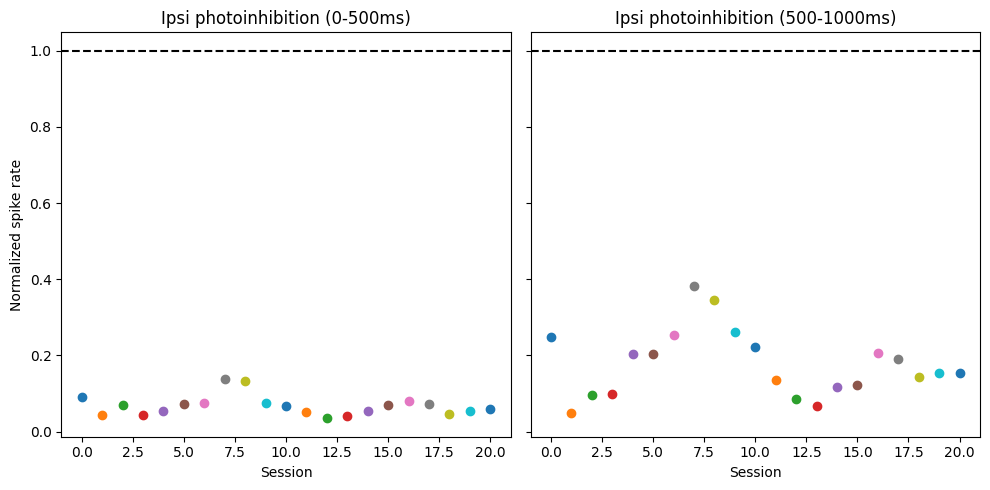

In [ ]:
# Plot as a single bar value for ipsi photoinhibition

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)

# First 500ms subplot
for i in range(len(all_ipsi_spks_first_500ms)):
    ratio = np.array(all_ipsi_spks_first_500ms[i][0]) / np.array(all_ipsi_spks_first_500ms[i][1])
    axes[0].scatter(i, np.mean(ratio))
axes[0].axhline(y=1, color='black', linestyle='--')
axes[0].set_xlabel('Session')
axes[0].set_ylabel('Normalized spike rate')
axes[0].set_title('Ipsi photoinhibition (0-500ms)')

# Last 500ms subplot
for i in range(len(all_ipsi_spks_last_500ms)):
    ratio = np.array(all_ipsi_spks_last_500ms[i][0]) / np.array(all_ipsi_spks_last_500ms[i][1])
    axes[1].scatter(i, np.mean(ratio))
axes[1].axhline(y=1, color='black', linestyle='--')
axes[1].set_xlabel('Session')
axes[1].set_title('Ipsi photoinhibition (500-1000ms)')

plt.tight_layout()
plt.show()



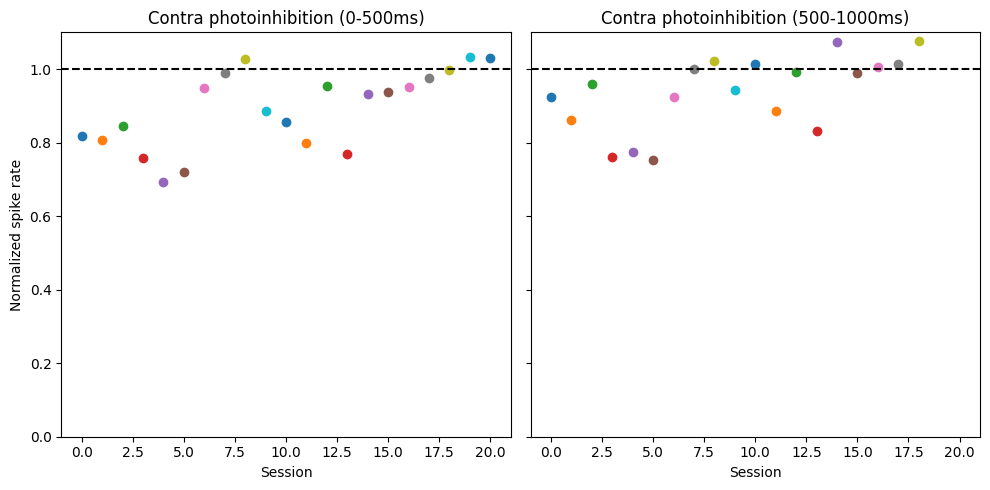

In [91]:
# Plot as a single bar value for contra photoinhibition

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)

# First 500ms subplot
for i in range(len(all_contra_spks_first_500ms)):
    ratio = np.array(all_contra_spks_first_500ms[i][0]) / np.array(all_contra_spks_first_500ms[i][1])
    axes[0].scatter(i, np.mean(ratio))
axes[0].axhline(y=1, color='black', linestyle='--')
axes[0].set_xlabel('Session')
axes[0].set_ylabel('Normalized spike rate')
axes[0].set_title('Contra photoinhibition (0-500ms)')

# Last 500ms subplot
for i in range(len(all_contra_spks_last_500ms)):
    ratio = np.array(all_contra_spks_last_500ms[i][0]) / np.array(all_contra_spks_last_500ms[i][1])
    axes[1].scatter(i, np.mean(ratio))
axes[1].axhline(y=1, color='black', linestyle='--')
axes[1].set_xlabel('Session')
axes[1].set_title('Contra photoinhibition (500-1000ms)')
plt.ylim(0, 1.1)
plt.tight_layout()
plt.show()

### Red laser - ChrimsonR

In [56]:
# Passive data at various powers
passive_red_paths = [
    r'H:\ephys_data\CW47\python\2024_10_19',
    r'H:\ephys_data\CW47\python\2024_10_20',
    r'H:\ephys_data\CW47\python\2024_10_21',
    r'H:\ephys_data\CW47\python\2024_10_22',
    r'H:\ephys_data\CW47\python\2024_10_23',
    r'H:\ephys_data\CW47\python\2024_10_24'
    ]

s1 = Session(passive_red_paths[0], passive=True, laser = 'red')




Remove 136 trials from session for bad behavior
2 trials removed for stability reasons
only ppyr neurons: 384 --> 64


c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\catherinewang\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [57]:
neuron_cell_type = np.where(s1.celltype == 3)[0]
neuron_cell_type = [n for n in neuron_cell_type if n in s1.L_alm_idx]

In [64]:
s1.all_stim_levels

[0.0, 1.4, 1.8, 2.1, 2.7]

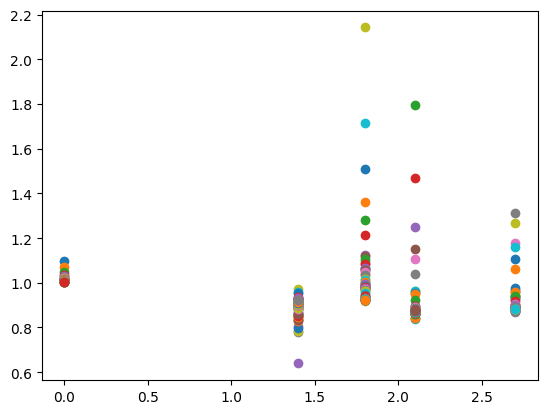

In [75]:
window = (0.570, 0.570 + 1.3 + 0.1)
control_trials = np.where(s1.stim_ON == False)[0] 

f = plt.figure()
# for i in range(len(s1.all_stim_levels)): 
#     level = s1.all_stim_levels[i]
all_spk_rates = []
for level in s1.all_stim_levels[:]:     
    avg_spk_rate = []
    for n in neuron_cell_type:
        stim_trials = np.where(s1.stim_level == level)[0]
        stim_trials = [c for c in stim_trials if c in s1.stable_trials[n]]
        
        baseline = s1.get_spike_rate(n, window, control_trials)
        
        avg_spk_rate += [s1.get_spike_rate(n, window, stim_trials) / baseline]

        plt.scatter(level, np.mean(avg_spk_rate), label = 'level {}'.format(level))

    all_spk_rates += [avg_spk_rate]

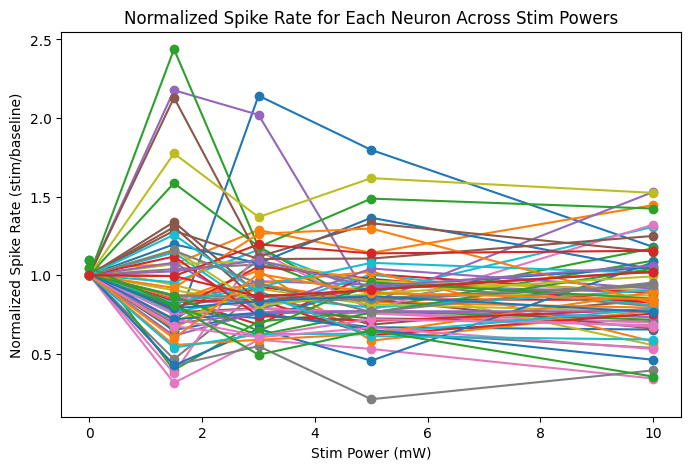

In [81]:
plt.figure(figsize=(8, 5))
for i, neuron_rates in enumerate(np.array(all_spk_rates).T):
    plt.plot([0, 1.5, 3, 5, 10], neuron_rates, marker='o', label=f'Neuron {i+1}')
plt.xlabel('Stim Power (mW)')
plt.ylabel('Normalized Spike Rate (stim/baseline)')
plt.title('Normalized Spike Rate for Each Neuron Across Stim Powers')
plt.show()

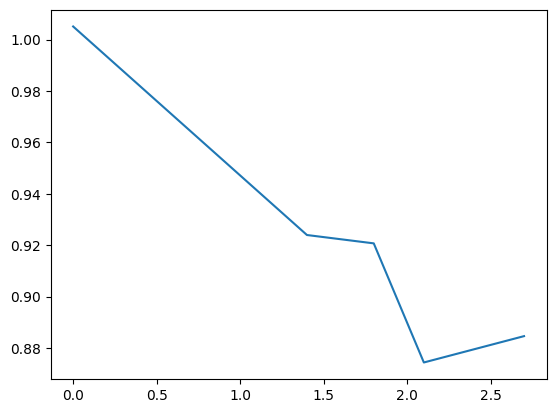

In [78]:
plt.plot(s1.all_stim_levels, np.mean(all_spk_rates, axis=1))

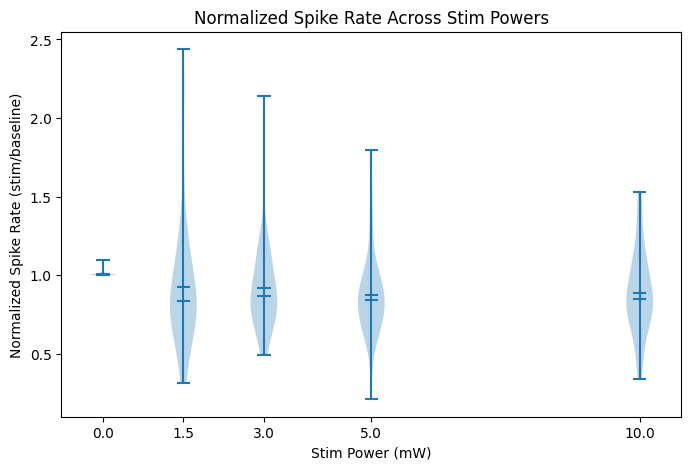

In [79]:
# No seaborn import or usage

# x positions for plotting, corresponding to stim powers [0, 1.5, 3.5, 10]. Adjust to match the number of stim levels you have.
stim_powers = [0, 1.5, 3, 5, 10]
data_for_violin = all_spk_rates[:len(stim_powers)]  # Crop if there are more!

plt.figure(figsize=(8, 5))
parts = plt.violinplot(data_for_violin, positions=stim_powers, widths=0.5, showmeans=True, showmedians=True)
plt.xticks(stim_powers)
plt.xlabel('Stim Power (mW)')
plt.ylabel('Normalized Spike Rate (stim/baseline)')
plt.title('Normalized Spike Rate Across Stim Powers')
plt.show()

### Activity changes under red laser pertubation

In [ ]:
red_laser_paths = [
    r'G:\ephys_data\CW59\python\2025_02_27',
    r'M:\data\CW91\python\2026_05_06',
    r'M:\data\CW89\python\2026_05_16',
    r'N:\data\CW98\python\2026_05_25',
    r'N:\data\CW88\python\2026_06_09',
]


In [ ]:
s1 = Session(red_laser_paths[3], side = 'L', passive=False, filter_low_perf=False, filter_by_stim=False, laser='red')


42 trials removed for stability reasons
only ppyr neurons: 312 --> 268


4 trials removed for stability reasons
only ppyr neurons: 102 --> 88
21 trials removed for stability reasons
only ppyr neurons: 170 --> 151
30 trials removed for stability reasons
only ppyr neurons: 205 --> 177
15 trials removed for stability reasons
only ppyr neurons: 186 --> 161
33 trials removed for stability reasons
only ppyr neurons: 89 --> 80


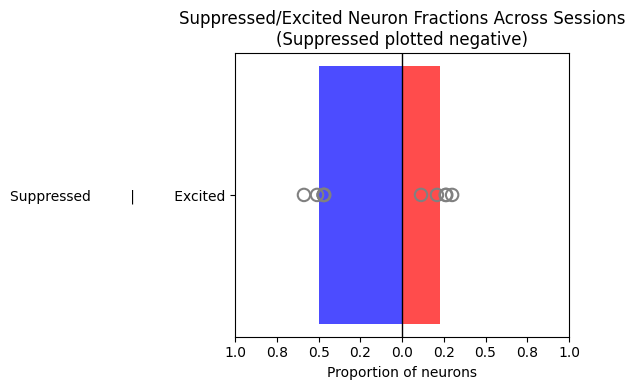

In [ ]:
# Gather fractions of suppressed and excited neurons for each session
frac_suppressed_list = []
frac_excited_list = []

for path in red_laser_paths:
    s1 = Session(path, side = 'L', passive=False, filter_low_perf=False, filter_by_stim=False, laser='red')

    stim_thresh = 2 if 'CW59' in path else 1
    window = (0.57, 0.57+2.3) if 'CW59' in path else (0.57, 0.57+1.7) # Behavior

    stim_trials = np.where(s1.stim_level > stim_thresh)[0]
    control_trials = np.where(s1.stim_level < stim_thresh)[0]

    sig_effect = []
    for n in s1.L_alm_idx:
        val = s1.stim_effect_per_neuron(n, stim_trials, window=window, p=0.0001)
        sig_effect += [val]    

    frac_supr = sum(np.array(sig_effect) == -1) / len(s1.L_alm_idx)
    frac_exc  = sum(np.array(sig_effect) == 1)  / len(s1.L_alm_idx)
    frac_suppressed_list.append(frac_supr)
    frac_excited_list.append(frac_exc)


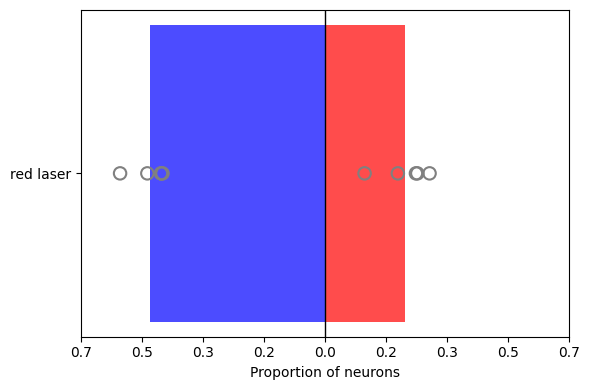

In [53]:
# Plot means as bars and individual session values as grey scatter dots (horizontal)
mean_frac_suppressed = np.mean(frac_suppressed_list)
mean_frac_excited = np.mean(frac_excited_list)

categories = ['Suppressed', 'Excited']
bar_vals = [mean_frac_suppressed, mean_frac_excited]

fig, ax = plt.subplots(figsize=(6, 4))

# Plot negative for suppressed, positive for excited (single row)
bar_vals_signed = [-mean_frac_suppressed, mean_frac_excited]
bar_labels = ['Suppressed', 'Excited']
# Bar positions: both on y=0 row, left=negative, right=positive
bars = ax.barh([0, 0], bar_vals_signed, color=['blue', 'red'], alpha=0.7, align='center', height=0.6)

# Add labels on bars
for bar, val, label in zip(bars, bar_vals_signed, bar_labels):
    xpos = bar.get_width() + (0.03 if val >= 0 else -0.03)
    ha = 'left' if val >= 0 else 'right'
    # Place label to the side of the bar end
    # ax.text(xpos, bar.get_y() + bar.get_height()/2, va='center', ha=ha, fontsize=13, fontweight='bold', color=bar.get_facecolor())

# Overlay grey scatter dots for each session, suppressed as negatives, excited as positives
ax.scatter(-np.array(frac_suppressed_list), np.zeros_like(frac_suppressed_list), 
            facecolors='none', edgecolors='grey', s=80, linewidths=1.5, zorder=3)
ax.scatter( np.array(frac_excited_list), np.zeros_like(frac_excited_list), 
            facecolors='none', edgecolors='grey', s=80, linewidths=1.5, zorder=3)

# x-tick labels and vertical line at 0 for separation
ax.axvline(0, color='black', lw=1)
xticks = np.linspace(-0.7, 0.7, 9)
ax.set_xticks(xticks)
ax.set_xticklabels([f"{abs(x):.1f}" for x in xticks])

# Labeling y
ax.set_yticks([0])
ax.set_yticklabels(['red laser'])
ax.set_xlabel('Proportion of neurons')
# No ax.set_xlim

plt.tight_layout()
plt.savefig(r'P:\paperfigures\fig5\red_laser_prop_affected.pdf')
plt.show()

4 trials removed for stability reasons
only ppyr neurons: 102 --> 88
21 trials removed for stability reasons
only ppyr neurons: 170 --> 151
30 trials removed for stability reasons
only ppyr neurons: 205 --> 177
15 trials removed for stability reasons
only ppyr neurons: 186 --> 161
33 trials removed for stability reasons
only ppyr neurons: 89 --> 80


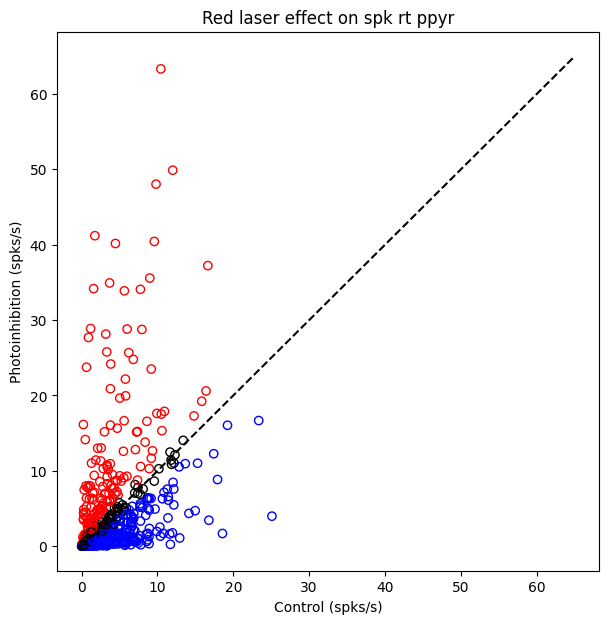

In [160]:
f = plt.figure(figsize=(7,7))

for path in red_laser_paths:
    s1 = Session(path, side = 'L', passive=False, filter_low_perf=False, filter_by_stim=False, laser='red')

    L_alm_fs = [n for n in s1.L_alm_idx if s1.celltype[n] == 3]

    stim_thresh = 2 if 'CW59' in path else 1
    window = (0.57, 0.57+2.3) if 'CW59' in path else (0.57, 0.57+1.7) # Behavior

    stim_trials = np.where(s1.stim_level > stim_thresh)[0]
    control_trials = np.where(s1.stim_level < stim_thresh)[0]

    # Plot control vs stim scatter
        
    stim_spk, ctl_spk = [],[]
    middle_neurons, pint = [], []
    norm_rate = []

    sig_effect = []
    for n in L_alm_fs:
        val = s1.stim_effect_per_neuron(n, stim_trials, window=window, p=0.0001)
        sig_effect += [val]   

    for i in range(len(L_alm_fs)):
        n = L_alm_fs[i]
        ctl_rate = s1.get_spike_rate(n, window, control_trials)
        # if ctl_rate < 1:
        #     continue
        stim_rate = s1.get_spike_rate(n, window, stim_trials)
        # if stim_rate/ctl_rate > 0.55: 
        #     continue
        # if stim_rate > ctl_rate: 
        #     pint = [n]
        #     continue
        stim_spk += [stim_rate]
        ctl_spk += [ctl_rate]
        
        norm_rate += [stim_rate / ctl_rate]
        
        # if stim_rate/ctl_rate > 0.4 and stim_rate/ctl_rate < 1:
        #     middle_neurons += [n]
        color='red' if sig_effect[i] == 1 else 'blue'
        if sig_effect[i] == 0:
            color = 'black'
        plt.scatter(ctl_rate, stim_rate, color=color,facecolors='none')

# plt.scatter(ctl_spk, stim_spk, color=color)
    
plt.plot([0, 65], [0, 65], ls='--', color='black')
plt.ylim
plt.ylabel('Photoinhibition (spks/s)')
plt.xlabel('Control (spks/s)')
plt.title('Red laser effect on spk rt ppyr')
plt.savefig(r'P:\paperfigures\fig5\red_laser_spkrt_scatter.pdf')
plt.show()